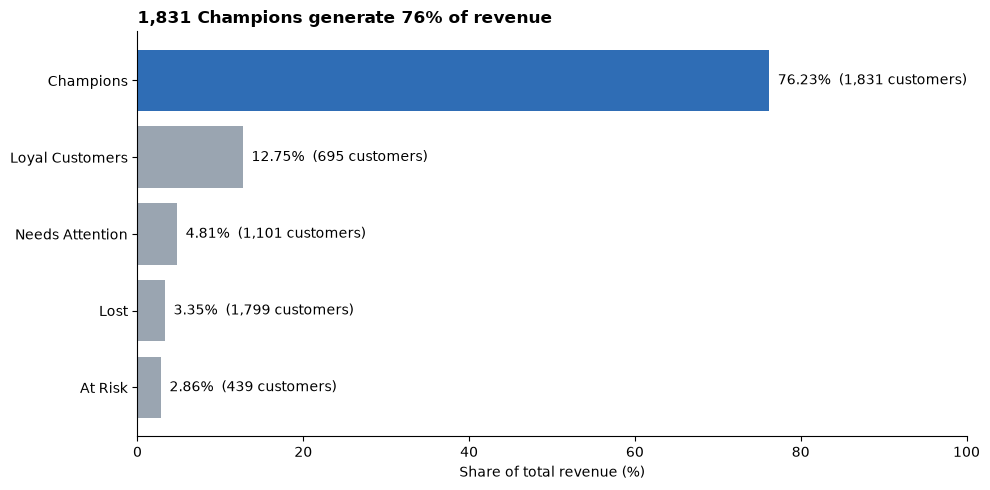

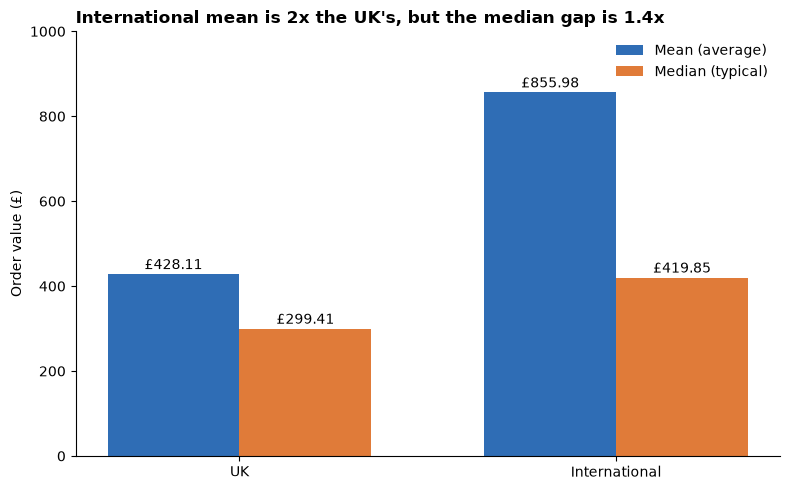

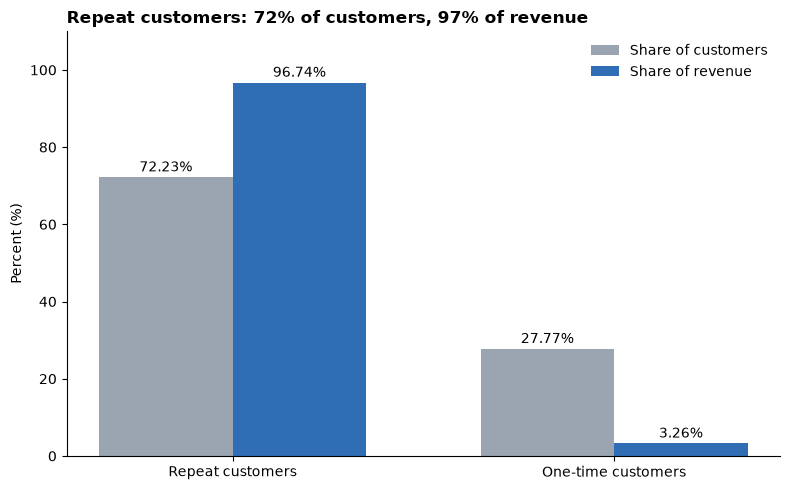

['monthly_revenue_trend.png', 'repeat_vs_one_time_revenue.png', 'rfm_segment_revenue_share.png', 'seasonal_revenue.png', 'uk_vs_international_order_value.png']


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("../visuals", exist_ok=True)
BLUE, ORANGE, GREY = "#2f6db5", "#e07b39", "#9aa5b1"

# Chart 1: RFM segment share of revenue
segments = ["Champions", "Loyal Customers", "Needs Attention", "Lost", "At Risk"]
customers = [1831, 695, 1101, 1799, 439]
revenue_pct = [76.23, 12.75, 4.81, 3.35, 2.86]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(segments[::-1], revenue_pct[::-1], color=[GREY]*4 + [BLUE])
for bar, pct, n in zip(bars, revenue_pct[::-1], customers[::-1]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
            f"{pct}%  ({n:,} customers)", va="center", fontsize=10)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of total revenue (%)")
ax.set_title("1,831 Champions generate 76% of revenue", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../visuals/rfm_segment_revenue_share.png", dpi=150)
plt.show()

# Chart 2: mean vs median order value, UK vs international
markets = ["UK", "International"]
mean_vals = [428.11, 855.98]
median_vals = [299.41, 419.85]
x = np.arange(2)
w = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w/2, mean_vals, w, label="Mean (average)", color=BLUE)
b2 = ax.bar(x + w/2, median_vals, w, label="Median (typical)", color=ORANGE)
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 12,
            f"£{b.get_height():,.2f}", ha="center", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(markets)
ax.set_ylabel("Order value (£)")
ax.set_ylim(0, 1000)
ax.set_title("International mean is 2x the UK's, but the median gap is 1.4x", loc="left", fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../visuals/uk_vs_international_order_value.png", dpi=150)
plt.show()

# Chart 3: repeat vs one-time customers, share of customers vs share of revenue
groups = ["Repeat customers", "One-time customers"]
cust_share = [72.23, 27.77]
rev_share = [96.74, 3.26]
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w/2, cust_share, w, label="Share of customers", color=GREY)
b2 = ax.bar(x + w/2, rev_share, w, label="Share of revenue", color=BLUE)
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5,
            f"{b.get_height()}%", ha="center", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel("Percent (%)")
ax.set_ylim(0, 110)
ax.set_title("Repeat customers: 72% of customers, 97% of revenue", loc="left", fontweight="bold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../visuals/repeat_vs_one_time_revenue.png", dpi=150)
plt.show()

print(sorted(os.listdir("../visuals")))

## Limitations

**Coverage**
- The data comes from a single UK-based online retailer and covers Dec 2009 to Dec 2011, so results may not generalise to other businesses.
- December 2011 contains only 9 days, so that month's revenue is understated. Seasonal conclusions rest on only two Novembers.

**Data quality**
- About 22.8% of rows (243,007) have no Customer ID, so guest purchases are excluded from customer-level analysis (repeat rate, RFM, revenue concentration). Those figures only describe identifiable customers.
- 486 product codes (1.84% of revenue, £362,819.20) have no usable description ("Unknown"). They are excluded from product-level results.
- Cancelled orders (about 1.8% of rows) were removed from revenue figures and analysed separately. The data gives no cancellation reasons, so any cause is a hypothesis.

**Analysis choices**
- All figures are revenue. The dataset has no cost, margin or shipping data, so profitability can't be assessed.
- RFM segment boundaries come from quartile scoring, and the segment labels are a judgement call. Different thresholds would move some customers between segments.
- "One-time buyers" may include recent customers whose second order falls after the data ends.
- Order-value averages are skewed by a few very large orders, so the median is reported alongside the mean for international vs UK.

**What the data cannot show**
- It is observational. The findings show patterns, not causes, and the recommendations are hypotheses to test, not proven actions.